In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgbm
# 데이터 분할 및 전처리
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 특성 선택
from sklearn.feature_selection import SequentialFeatureSelector

# 하이퍼파라미터 튜닝
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve
# 모델 평가 지표
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# 데이터 시각화
import seaborn as sns

#파이프라인 / encoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, FunctionTransformer
from lightgbm import LGBMClassifier


# 1. 데이터 로드

In [3]:
df_trn = pd.read_csv('train.csv')
df_tst = pd.read_csv('test.csv')

In [5]:
# 범주형 데이터를 라벨 인코딩
cat = ['job','marital','contact','poutcome','education','default','housing','loan','month']
label_encoder = {}
for col in cat:
    le = LabelEncoder()
    df_trn[col] = le.fit_transform(df_trn[col])
    df_tst[col] = le.transform(df_tst[col])
    label_encoder[col] = le

#### 2.2 파생 변수 생성

In [6]:
# 계절을 반환하는 함수 정의

def month_to_num(X):
    return X.replace(month_map)

month_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('mapper', FunctionTransformer(month_to_num)),
])

def get_season(month):
    if 3 <= month <= 5:
        return 'spring'
    elif 6 <= month <= 8:
        return 'summer'
    elif 9 <= month <= 11:
        return 'autumn'
    else:
        return 'winter'

NameError: name 'SimpleImputer' is not defined

In [ ]:
# 데이터 전처리 함수 정의
def preprocess_data(df_trn, df_tst):

    le = LabelEncoder()
    
    # pdays 를 갖고 연락여부로 이진분류한 새로운 칼럼 생성
    df_trn['pdays_contacted'] = (df_trn['pdays'] != -1).astype(int)
    df_tst['pdays_contacted'] = (df_tst['pdays'] != -1).astype(int)
    
    # 흠....
    df_trn['duration_per_campaign'] = df_trn['duration'] / (df_trn['campaign'] + 1)
    df_tst['duration_per_campaign'] = df_tst['duration'] / (df_tst['campaign'] + 1)
    
    # day와 month를 통합하여 연속적인 시간 정보를 제공하기 위한 새로운 칼럼 생성
    df_trn['day_of_year'] = df_trn['day'] + (df_trn['month'] - 1) * 30
    df_tst['day_of_year'] = df_tst['day'] + (df_tst['month'] - 1) * 30
    
    # 계별 특성을 학습할 수 있도록 새로운 칼럼 생성
    df_trn['season'] = df_trn['month'].apply(get_season)
    df_tst['season'] = df_tst['month'].apply(get_season)
    # 범주형인 season을 라벨인코딩 수행
    df_trn['season'] = le.fit_transform(df_trn['season'])
    df_tst['season'] = le.transform(df_tst['season'])
    
    return df_trn, df_tst

In [ ]:
# 전처리 함수 적용 후 할당
df_trn_preprocessed, df_tst_preprocessed = preprocess_data(df_trn,df_tst)

#### 2.3 Feature와 Target 분리

In [ ]:
total_cols = [x for x in df_trn.columns]

id_cols = ['ID']
y_cols = ['label']
x_cols = [x for x in total_cols if x not in id_cols+y_cols]

In [ ]:
# feature와 target분리
df_trn_x = df_trn_preprocessed[x_cols]
df_trn_y = df_trn_preprocessed[y_cols].values.ravel()
df_tst_x = df_tst_preprocessed[x_cols]

In [ ]:
df_trn_x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31647 entries, 0 to 31646
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    31647 non-null  int64  
 1   job                    31647 non-null  int64  
 2   marital                31647 non-null  int64  
 3   education              31647 non-null  int64  
 4   default                31647 non-null  int64  
 5   balance                31647 non-null  int64  
 6   housing                31647 non-null  int64  
 7   loan                   31647 non-null  int64  
 8   contact                31647 non-null  int64  
 9   day                    31647 non-null  int64  
 10  month                  31647 non-null  int64  
 11  duration               31647 non-null  int64  
 12  campaign               31647 non-null  int64  
 13  pdays                  31647 non-null  int64  
 14  previous               31647 non-null  int64  
 15  po

### 3. 모델 정의 및 학습

#### 3.1 검증 데이터 분리

In [ ]:
# 검증 데이터셋 분리
df_retrn_x, df_val_x, df_retrn_y, df_val_y = train_test_split(df_trn_x, df_trn_y, test_size=0.2, random_state=42, stratify=df_trn_y)

#### 3.2 초기 모델 정의 및 학습

In [ ]:
# 초기 모델 정의
base_model = lgbm.LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced')
#학습
base_model.fit(df_retrn_x, df_retrn_y)

LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1)

In [105]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split( X, y, test_size=0.2, stratify=y, )


In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31647 entries, 0 to 31646
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        31647 non-null  int64 
 1   job        31647 non-null  object
 2   marital    31647 non-null  object
 3   education  31647 non-null  object
 4   default    31647 non-null  object
 5   balance    31647 non-null  int64 
 6   housing    31647 non-null  object
 7   loan       31647 non-null  object
 8   contact    31647 non-null  object
 9   day        31647 non-null  int64 
 10  month      31647 non-null  object
 11  campaign   31647 non-null  int64 
 12  pdays      31647 non-null  int64 
 13  previous   31647 non-null  int64 
 14  poutcome   31647 non-null  object
 15  label      31647 non-null  int64 
dtypes: int64(7), object(9)
memory usage: 3.9+ MB


# 파생변수 생성(함수)

## 수치형 변수 (로그변환해야하는 이유)

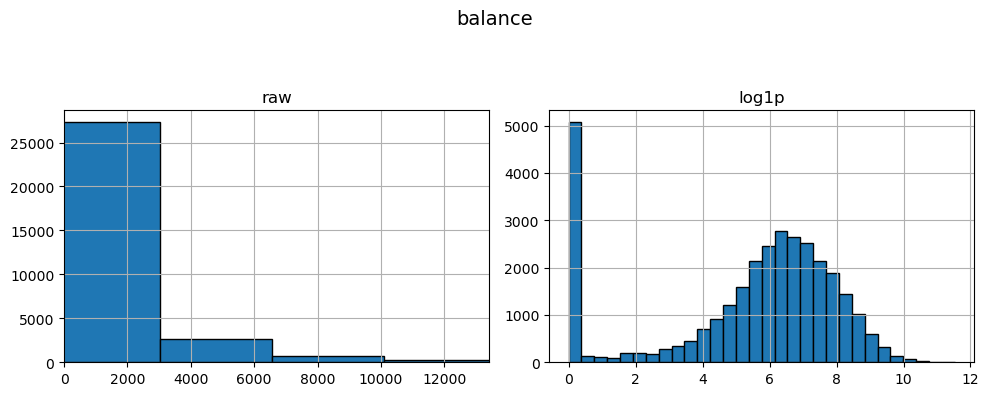

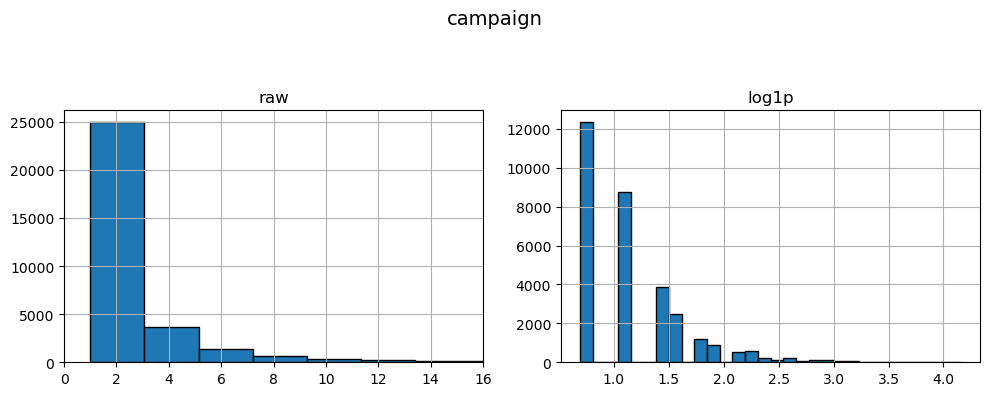

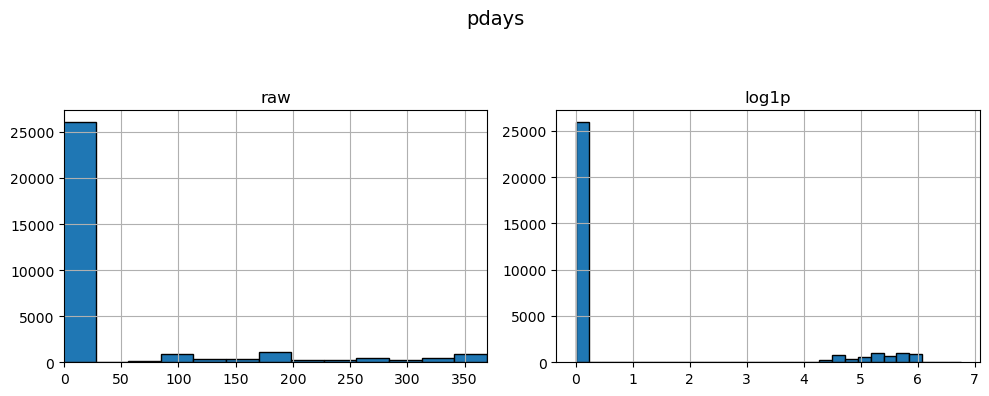

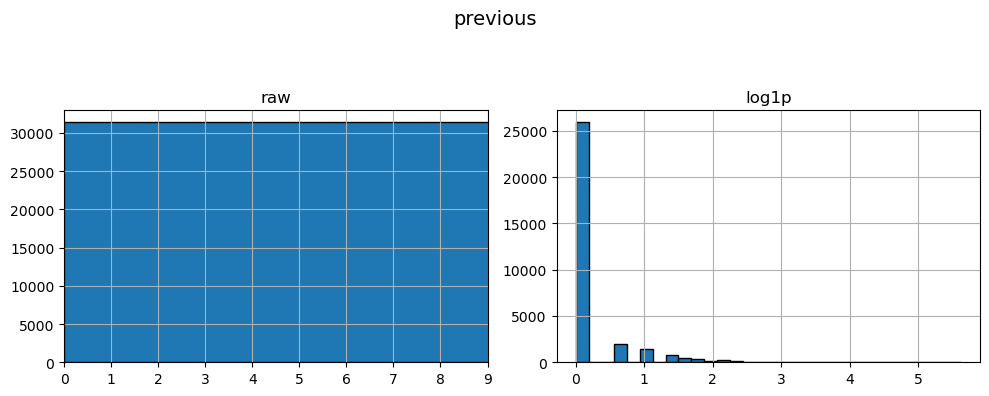

In [107]:
import matplotlib.pyplot as plt
import numpy as np

num_cols = ['balance','campaign','pdays','previous']

for col in num_cols:
    data = df[col].copy()
    
    # 1) 로그 변환분과 원본 비교를 위한 서브플롯
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(col, fontsize=14)
    
    #  원본 분포 — x축 제한
    axes[0].hist(data, bins=30, edgecolor='k')
    axes[0].set_title('raw')
    axes[0].set_xlim(0, np.percentile(data.replace(999, np.nan).dropna(), 99))  
    # 99백분위까지만 잘라서 메인 분포 확인
    axes[0].grid(True)
    
    # 로그1p 변환 후
    log_data = np.log1p(data.clip(lower=0))
    axes[1].hist(log_data, bins=30, edgecolor='k')
    axes[1].set_title('log1p')
    axes[1].grid(True)
    
    plt.tight_layout(rect=[0, 0, 1, 0.9])
    plt.show()


In [108]:
month_map = {
    'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
    'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12
}
def get_season(month_num):
    if 3 <= month_num <= 5:   return 'spring'
    if 6 <= month_num <= 8:   return 'summer'
    if 9 <= month_num <= 11:  return 'autumn'
    return 'winter'

In [109]:
def combined_feat_eng(df):
    df = df.copy()
    
    # 1) education → 순서형
    edu_map = {'unknown':0, 'primary':1, 'secondary':2, 'tertiary':3}
    df['education_ord'] = df['education'].map(edu_map)
    
    # 2) marital 플래그
    df['is_single']   = (df['marital']=='single').astype(int)
    df['is_married']  = (df['marital']=='married').astype(int)
    df['is_divorced'] = (df['marital']=='divorced').astype(int)
    
    # 3) job 그룹화
    job_map = {
        'blue-collar':'manual', 'housemaid':'manual',
        'services':'service',  'technician':'service',
        'admin.':'whitecollar','management':'whitecollar','self-employed':'whitecollar',
        'retired':'retired',   'student':'student', 'unemployed':'unemployed',
        'entrepreneur':'other','unknown':'other'
    }
    df['job_grp'] = df['job'].map(job_map)
    
    # 4) balance 로그 변환
    min_bal = df['balance'].min()
    df['balance_shifted'] = df['balance'] - min_bal + 1
    df['balance_log']     = np.log(df['balance_shifted'])
    
    # 5) campaign 구간화(변화)
    df['campaign_log'] = np.log1p(df['campaign'])
    
    # 6) pdays → 이진+구간
    df['was_contacted'] = (df['pdays'] != -1).astype(int)    
    df['pdays_bin'] = pd.cut(
        df['pdays'],
        bins=[-1,0,30,180,999],
        labels=['no_contact','<=1m','1m-6m','>6m']
    )
    
    # 7) credit 통합
    df['any_credit'] = ((df['housing']=='yes') | (df['loan']=='yes')).astype(int)
    
    # 8) day 순환 변환
    m = df['day']
    df['day_sin'] = np.sin(2*np.pi * m / 31)
    df['day_cos'] = np.cos(2*np.pi * m / 31)

    month_map = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
                 'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
    m = df['month'].map(month_map)
    df['month_sin'] = np.sin(2*np.pi * m / 12)
    df['month_cos'] = np.cos(2*np.pi * m / 12)


    # 10) default 플래그
    df['is_default'] = (df['default']=='yes').astype(int)
    
    #11) precious 로그변환(변화)
    df['previous_log']  = np.log1p(df['previous'])
    
    return df

In [110]:
feat_trans = FunctionTransformer(combined_feat_eng, validate=False)

# 숫자형 칼럼
num_cols = [
    'education_ord',
    'balance_log',
    'day_sin', 'day_cos',
    'month_sin', 'month_cos',
    'is_single', 'is_married', 'is_divorced',
    'any_credit', 'was_contacted', 'is_default',
    'previous_log', 'age', 'campaign_log'
]

# 범주형 칼럼
cat_cols = ['job_grp','pdays_bin','poutcome','contact']

# 3) 숫자형 파이프라인: 스케일링
num_pipeline = Pipeline([
    ("scale", StandardScaler())
])

# 4) 범주형 파이프라인: 원-핫 인코딩
cat_pipeline = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# 5) ColumnTransformer: 숫자·범주형 묶어서 전처리
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline,  cat_cols),
    ],
    remainder="drop",                
    verbose_feature_names_out=False  
)

 

In [111]:
from imblearn.combine import SMOTETomek
from imblearn.pipeline        import Pipeline as ImbPipeline

ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

pipeline = ImbPipeline([
    ("feat_trans",   FunctionTransformer(combined_feat_eng, validate=False)),
    ("preprocess", preprocessor),            # ColumnTransformer
    ("clf",        LGBMClassifier(class_weight={0:1, 1:ratio},random_state=42))
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

pipeline.fit(X_train, y_train)


[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001299 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 531
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 33
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


Pipeline(steps=[('feat_trans',
                 FunctionTransformer(func=<function combined_feat_eng at 0x343792a20>)),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['education_ord',
                                                   'balance_log', 'day_sin',
                                                   'day_cos', 'month_sin',
                                                   'month_cos', 'is_single',
                                                   'is_married', 'is_divorced',
                                                   'any_credit',
                                                   'was_contacted',
                                                   'is_default', 'previous_log',
                                                   'age', 'campaign_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['job_grp', 'pdays_bin',
                                                   'poutcome', 'contact'])],
                                   verbose_feature_names_out=False)),
                ('clf',
                 LGBMClassifier(class_weight={0: 1,
                                              1: np.float64(7.547265361242403)},
                                random_state=42))])

In [112]:
y_pred = pipeline.predict(X_val)
print("F1-score:", f1_score(y_val, y_pred))

F1-score: 0.4092186621697583


- F1-score: 0.33104799216454456 
    - 이 f1 day 와 month 에 대해 순환 처리 cos, sin 에 대해 했을 때 f1 스코어

- (r)F1-score: 0.3241706161137441
    - month 에 대해서 summer , winter, vacation 으로 나눴을 떄 f1 스코어

ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

pipeline = ImbPipeline([
    ("feat_eng",   FunctionTransformer(combined_feat_eng, validate=False)),
    ("preprocess", preprocessor),            # ColumnTransformer
    ("clf",        LGBMClassifier(class_weight={0:1, 1:ratio},random_state=42))
])

- 이렇게 가져 갔을 때, F1스코어가 완전히 높아졌음 value counts 한 다음에 weight 주는게 좋은 방향일수도!

- 변화했을 때, 0.3971462544589774


- 0.4092186621697583
    - 기존 변수 빠진거 추가하고 학습 진행

In [ ]:
#!pip install shap

## SHAP 적용 (GPT!)

- Feature Selection 위해 사용

In [ ]:
import numpy as np
import pandas as pd
import shap

# 1) Pipeline에서 모델·전처리기 꺼내기
base_model   = pipeline.named_steps['clf']
preprocessor = pipeline.named_steps['preprocess']
feat_trans   = pipeline.named_steps['feat_trans']

# 2) 원본 훈련 데이터를 파생→전처리
X_eng  = feat_trans.transform(X_train)              
X_proc = preprocessor.transform(X_eng)              

# 3) 전처리 후 피처명
feature_names = preprocessor.get_feature_names_out()

# 4) DataFrame으로 재구성
df_proc = pd.DataFrame(X_proc, columns=feature_names)

# 5) SHAP Explainer 생성
explainer   = shap.TreeExplainer(base_model)
shap_values = explainer.shap_values(df_proc)

# 6) shap_values가 리스트인지, 배열인지 확인
if isinstance(shap_values, list):
    # 예전 방식: [neg_class, pos_class]
    shap_array = shap_values[1]
else:
    # 최신 방식: 바로 (n_samples, n_features)
    shap_array = shap_values

# 7) 각 피처별 평균 절댓값 계산
shap_imp = np.abs(shap_array).mean(axis=0)

# 8) DataFrame으로 정리
imp_df = pd.DataFrame({
    'feature': feature_names,
    'shap_imp': shap_imp
}).sort_values('shap_imp', ascending=False)

print(imp_df.head(20))


             feature  shap_imp
9         any_credit  0.217724
1        balance_log  0.216169
32   contact_unknown  0.211959
30  contact_cellular  0.205241
5          month_cos  0.204731
28  poutcome_success  0.166394
14      campaign_log  0.156048
2            day_sin  0.125812
13               age  0.104149
3            day_cos  0.096881
7         is_married  0.093716
4          month_sin  0.074375
0      education_ord  0.063191
26  poutcome_failure  0.032855
24     pdays_bin_>6m  0.031308
10     was_contacted  0.023886
8        is_divorced  0.023045
18   job_grp_service  0.022051
15    job_grp_manual  0.018842
12      previous_log  0.017962


In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score

# 1) SHAP 임포턴스 중앙값(threshold) 계산
threshold = imp_df['shap_imp'].median()
print("SHAP median:", threshold)

# 2) 중앙값 이상인 피처 리스트 추출
selected = imp_df.loc[imp_df['shap_imp'] >= threshold, 'feature'].tolist()
print(f"Selected {len(selected)} features:", selected)

# 3) 파이프라인 변환기들 꺼내기
feat_trans   = pipeline.named_steps['feat_trans']
preprocessor = pipeline.named_steps['preprocess']

# 4) 데이터 변환
X_train_eng = feat_trans.transform(X_train)
X_val_eng   = feat_trans.transform(X_val)

X_train_proc = preprocessor.transform(X_train_eng)
X_val_proc   = preprocessor.transform(X_val_eng)

feat_names = preprocessor.get_feature_names_out()
df_trn_proc = pd.DataFrame(X_train_proc, columns=feat_names)
df_val_proc = pd.DataFrame(X_val_proc,   columns=feat_names)

# 5) 선택된 피처만
X_trn_sel = df_trn_proc[selected]
X_val_sel = df_val_proc[selected]

# 6) 모델 학습·평가
model_sel = LGBMClassifier(class_weight={0:1, 1:ratio}, random_state=42)
model_sel.fit(X_trn_sel, y_train)
y_pred_sel = model_sel.predict(X_val_sel)

print("F1 (median-threshold features):", f1_score(y_val, y_pred_sel))


SHAP median: 0.023044682027062273
Selected 17 features: ['any_credit', 'balance_log', 'contact_unknown', 'contact_cellular', 'month_cos', 'poutcome_success', 'campaign_log', 'day_sin', 'age', 'day_cos', 'is_married', 'month_sin', 'education_ord', 'poutcome_failure', 'pdays_bin_>6m', 'was_contacted', 'is_divorced']
[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000824 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 470
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
F1 (median-threshold features): 0.4043243243243243


In [113]:
from sklearn.metrics import precision_recall_curve

# 1) 밸리데이션 세트에 대한 예측 확률
y_proba = pipeline.predict_proba(X_val)[:,1]

# 2) precision–recall 커브에서 F1 계산
prec, rec, thr = precision_recall_curve(y_val, y_proba)
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
best_idx = f1_scores.argmax()
best_threshold = thr[best_idx]
print(f"Best threshold={best_threshold:.3f}, F1={f1_scores[best_idx]:.4f}")

# 3) 이 임계값으로 재분류
y_pred_opt = (y_proba >= best_threshold).astype(int)
print("Optimized F1:", f1_score(y_val, y_pred_opt))


Best threshold=0.581, F1=0.4215
Optimized F1: 0.42153644123440576


In [ ]:
#Best threshold=0.215, F1=0.4270
# Optimized F1: 0.42699724517906334




- (r)근데 ratio 로 ImbPipeline 설정했을 때 threshold 값이 안나오긴 하네염..

In [ ]:
#Best threshold=0.601, F1=0.4203
#Optimized F1: 0.4203102961918195

- 기존 변수 추가 임계값 최적화
    - Best threshold=0.581, F1=0.4215
    - Optimized F1: 0.42153644123440576

# Threshold

In [115]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline       import Pipeline as ImbPipeline
from lightgbm                import LGBMClassifier
from sklearn.metrics         import precision_recall_curve, f1_score

# 1) 공통 전처리 스텝
feat_trans   = pipeline.named_steps['feat_trans']
preprocessor = pipeline.named_steps['preprocess']

prefix = [
    ("feat_trans", feat_trans),
    ("preprocess", preprocessor),
]

# 2) 설정별 모델/샘플러 정의
ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

configs = {
    "balanced_weight":  LGBMClassifier(class_weight="balanced", random_state=42),
    "scale_pos_weight": LGBMClassifier(scale_pos_weight=ratio,  random_state=42),
    "ROS_0.3":          ImbPipeline(prefix + [("ros", RandomOverSampler(sampling_strategy=0.3, random_state=42)),
                                             ("clf", LGBMClassifier(random_state=42))]),
    "SMOTE_0.3":        ImbPipeline(prefix + [("smt", SMOTE(sampling_strategy=0.3, random_state=42)),
                                             ("clf", LGBMClassifier(random_state=42))]),
}

# 3) 평가용 함수
def eval_config(model, X_tr, y_tr, X_va, y_va):
    # 파이프라인이 아니면 래핑
    pipe = model if hasattr(model, "fit") and isinstance(model, ImbPipeline) else \
           ImbPipeline(prefix + [("clf", model)])
    pipe.fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_va)[:,1]
    prec, rec, thr = precision_recall_curve(y_va, proba)
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    idx = f1s.argmax()
    return thr[idx], f1s[idx]

# 4) 반복 실행 및 결과 출력
for name, cfg in configs.items():
    best_thr, best_f1 = eval_config(cfg, X_train, y_train, X_val, y_val)
    print(f"{name:15s} → Best thr = {best_thr:.3f},  F1 = {best_f1:.4f}")


[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002990 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 531
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 33
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
balanced_weight → Best thr = 0.581,  F1 = 0.4215
[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001500 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 531
[LightGBM] [Info] Number of data points in the train set: 25317, num

# OPTUNA

import optuna
import numpy as np
from imblearn.pipeline        import Pipeline as ImbPipeline
from imblearn.over_sampling   import RandomOverSampler, SMOTE
from lightgbm                 import LGBMClassifier
from sklearn.metrics          import precision_recall_curve
from optuna.samplers          import TPESampler
from optuna.pruners           import MedianPruner

# 전처리 스텝 꺼내두기
feat_trans, preprocessor = pipeline.named_steps['feat_trans'], pipeline.named_steps['preprocess']
ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

def objective(trial):
    # ─── 샘플링 전략 ─────────────────────────
    sampler = trial.suggest_categorical('sampler', ['none', 'ROS', 'SMOTE'])
    strat   = trial.suggest_float('sampling_strategy', 0.1, 0.5)
    
    # ─── LightGBM 하이퍼파라미터 ───────────────
    params = {
        'n_estimators':   trial.suggest_int   ('n_estimators', 100, 1000, step=100),
        'learning_rate':  trial.suggest_float ('learning_rate', 1e-4, 1e-1, log=True),
        'num_leaves':     trial.suggest_int   ('num_leaves', 16, 128, step=16),
        'max_depth':      trial.suggest_int   ('max_depth', 3, 12),
        'reg_alpha':      trial.suggest_float ('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda':     trial.suggest_float ('reg_lambda', 1e-3, 10.0, log=True),
        'colsample_bytree':trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'subsample':      trial.suggest_float ('subsample', 0.5, 1.0),
    }
    
    # ─── 클래스 불균형 보정 ─────────────────────
    use_scale = trial.suggest_categorical('balance_method', ['class_weight','scale_pos_weight'])
    if use_scale=='scale_pos_weight':
        params['scale_pos_weight'] = ratio
    else:
        params['class_weight'] = 'balanced'
    
    # ─── 파이프라인 구성 ────────────────────────
    steps = [
        ('feat_trans', feat_trans),
        ('preprocess', preprocessor)
    ]
    if sampler=='ROS':
        steps.append(('ros', RandomOverSampler(sampling_strategy=strat, random_state=42)))
    elif sampler=='SMOTE':
        steps.append(('smt', SMOTE(sampling_strategy=strat, random_state=42)))
    steps.append(('clf', LGBMClassifier(random_state=42, **params)))
    pipe = ImbPipeline(steps)
    
    # ─── 학습 및 평가 ───────────────────────────
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:,1]
    prec, rec, thr = precision_recall_curve(y_val, proba)
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    return f1s.max()

# Study 생성 (TPE + MedianPruner)
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=10)
)
study.optimize(objective, n_trials=50, timeout=60*30)


In [ ]:
print("▶ Best F1:", study.best_value)
print("▶ Best params:", study.best_params)
#▶ Best F1: 0.4039334341906203
#▶ Best params: {'n_estimators': 100, 'learning_rate': 0.002472018585782415, 'num_leaves': 128, 'max_depth': 8, 'reg_alpha': 0.9461518466003893, 'reg_lambda': 6.505973118143229, 'colsample_bytree': 0.8939345644600866, 'subsample': 0.5911559831034492}
#▶ Best F1: 0.4516539435220688
#▶ Best params: {'sampler': 'SMOTE', 'sampling_strategy': 0.17692711138685285, 'n_estimators': 600, 'learning_rate': 0.0009668164738562177, 'num_leaves': 96, 'max_depth': 12, 'reg_alpha': 0.010945869150127106, 'reg_lambda': 2.1278957448918465, 'colsample_bytree': 0.8488197025146029, 'subsample': 0.9914855962151508, 'balance_method': 'class_weight'}

In [ ]:
# 1) import the Matplotlib version
from optuna.visualization import plot_optimization_history
fig = plot_optimization_history(study)
fig.show()




In [ ]:
print("▶ Best F1:", study.best_value)
print("▶ Best params:", study.best_params)

In [ ]:
from optuna.visualization import plot_parallel_coordinate
fig = plot_parallel_coordinate(study, params=['learning_rate','num_leaves','subsample'])
fig.show(renderer="svg")


In [ ]:
# pip install -U kaleido

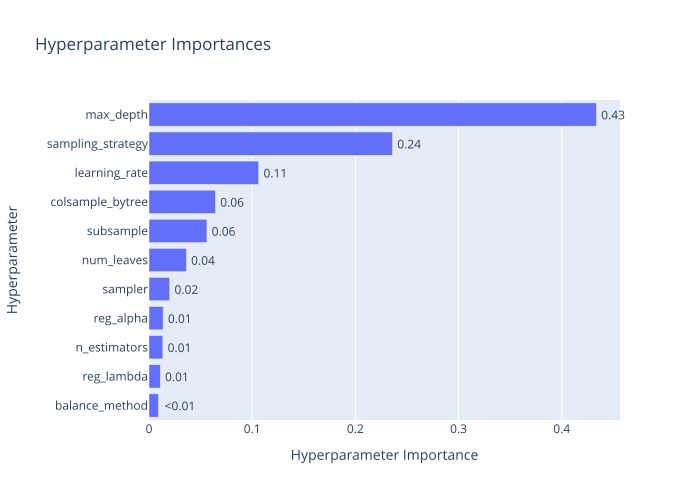

In [ ]:
from optuna.visualization import plot_param_importances
fig = plot_param_importances(study)
fig.show(renderer="svg")


In [125]:
import optuna
from optuna.samplers     import TPESampler
from optuna.pruners      import MedianPruner
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline     import Pipeline as ImbPipeline
from lightgbm              import LGBMClassifier
from sklearn.metrics       import precision_recall_curve

feat_trans, preprocessor = pipeline.named_steps['feat_trans'], pipeline.named_steps['preprocess']
ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

def objective(trial):
    # 1) 주요 하이퍼파라미터
    max_depth     = trial.suggest_int('max_depth', 10, 14)
    minority_rate = y_train.value_counts(normalize=True)[1]  # ≈0.117
    samp_strat    = trial.suggest_float('sampling_strategy',
                                        minority_rate + 1e-3,
                                        0.5)
    lr            = trial.suggest_float('learning_rate', 1e-4, 5e-3, log=True)
    csbt          = trial.suggest_float('colsample_bytree', 0.7, 1.0)
    ss            = trial.suggest_float('subsample', 0.7, 1.0)

    params = dict(
        n_estimators=600,
        num_leaves=96,
        reg_alpha=0.0109,
        reg_lambda=2.1279,
        max_depth=max_depth,
        learning_rate=lr,
        colsample_bytree=csbt,
        subsample=ss,
        class_weight='balanced',
        random_state=42
    )

    # 2) 샘플러 옵션 선택
    sampler = trial.suggest_categorical('sampler', ['none', 'ROS', 'SMOTE'])

    steps = [
        ('feat_trans', feat_trans),
        ('preprocess', preprocessor),
    ]

    if sampler == 'ROS':
        steps.append(('ros', RandomOverSampler(
            sampling_strategy=samp_strat, random_state=42)))
    elif sampler == 'SMOTE':
        # SMOTE는 here only
        steps.append(('smt', SMOTE(
            sampling_strategy=samp_strat, random_state=42)))

    steps.append(('clf', LGBMClassifier(**params)))
    pipe = ImbPipeline(steps)

    # 3) 학습·평가 (threshold 튜닝)
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:, 1]
    prec, rec, thr = precision_recall_curve(y_val, proba)
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    return f1s.max()



In [126]:
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=20)
)
study.optimize(objective, n_trials=80, timeout=60*60)

[I 2025-05-26 22:46:21,943] A new study created in memory with name: no-name-982b1fc5-7407-4968-87ff-cd7ee4290c84


[LightGBM] [Info] Number of positive: 10756, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003115 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6324
[LightGBM] [Info] Number of data points in the train set: 33111, number of used features: 33
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


[I 2025-05-26 22:46:30,253] Trial 0 finished with value: 0.41257861585459443 and parameters: {'max_depth': 11, 'sampling_strategy': 0.48117269178845723, 'learning_rate': 0.0017524101118128151, 'colsample_bytree': 0.8795975452591109, 'subsample': 0.7468055921327309, 'sampler': 'SMOTE'}. Best is trial 0 with value: 0.41257861585459443.


[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001218 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 531
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 33
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


[I 2025-05-26 22:46:38,345] Trial 1 finished with value: 0.43127672522237553 and parameters: {'max_depth': 13, 'sampling_strategy': 0.38848269846930095, 'learning_rate': 0.00010838581269344756, 'colsample_bytree': 0.9909729556485983, 'subsample': 0.9497327922401265, 'sampler': 'none'}. Best is trial 1 with value: 0.43127672522237553.


...

[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001216 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 531
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 33
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


[I 2025-05-26 23:00:15,537] Trial 78 finished with value: 0.453115899334803 and parameters: {'max_depth': 14, 'sampling_strategy': 0.4357961009597323, 'learning_rate': 0.0011400724825696886, 'colsample_bytree': 0.7933695428633367, 'subsample': 0.931012062188327, 'sampler': 'none'}. Best is trial 22 with value: 0.4544378693302055.


[LightGBM] [Info] Number of positive: 9756, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001905 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6308
[LightGBM] [Info] Number of data points in the train set: 32111, number of used features: 33
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


[I 2025-05-26 23:00:24,493] Trial 79 finished with value: 0.4313205038133655 and parameters: {'max_depth': 14, 'sampling_strategy': 0.4364472525968895, 'learning_rate': 0.0008421588807770336, 'colsample_bytree': 0.7950306180043692, 'subsample': 0.9384619416829637, 'sampler': 'SMOTE'}. Best is trial 22 with value: 0.4544378693302055.


▶ Best F1: 0.4544378693302055
▶ Best params: {'max_depth': 13, 'sampling_strategy': 0.17291843025169035, 'learning_rate': 0.0011354627706302205, 'colsample_bytree': 0.7767721301522258, 'subsample': 0.7354312209552957, 'sampler': 'none'}


In [127]:
print("▶ Best F1:", study.best_value)
print("▶ Best params:", study.best_params)

▶ Best F1: 0.4544378693302055
▶ Best params: {'max_depth': 13, 'sampling_strategy': 0.17291843025169035, 'learning_rate': 0.0011354627706302205, 'colsample_bytree': 0.7767721301522258, 'subsample': 0.7354312209552957, 'sampler': 'none'}


In [ ]:
#▶ Best F1: 0.4039334341906203
#▶ Best params: {'n_estimators': 100, 'learning_rate': 0.002472018585782415, 'num_leaves': 128, 'max_depth': 8, 'reg_alpha': 0.9461518466003893, 'reg_lambda': 6.505973118143229, 'colsample_bytree': 0.8939345644600866, 'subsample': 0.5911559831034492}

In [ ]:
#▶ Best F1: 0.4516539435220688
#▶ Best params: {'sampler': 'SMOTE', 'sampling_strategy': 0.17692711138685285, 'n_estimators': 600, 'learning_rate': 0.0009668164738562177, 'num_leaves': 96, 'max_depth': 12, 'reg_alpha': 0.010945869150127106, 'reg_lambda': 2.1278957448918465, 'colsample_bytree': 0.8488197025146029, 'subsample': 0.9914855962151508, 'balance_method': 'class_weight'}

In [ ]:
# 1) import the Matplotlib version
from optuna.visualization import plot_optimization_history
fig = plot_optimization_history(study)
fig.show()

# 하이퍼파라미터 튜닝

In [ ]:
y.value_counts(normalize=True)

label
0    0.883022
1    0.116978
Name: proportion, dtype: float64